Python: 3.13.16
PyTorch: 2.11.0+cpu
Transformers: 4.46.3
GPU available: False


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


BERT sentiment model loaded!

TOKENIZATION
Text: I love this amazing chicken restaurant!
Tokens: ['i', 'love', 'this', 'amazing', 'chicken', 'restaurant', '!']
Token IDs: [1045, 2293, 2023, 6429, 7975, 4825, 999]
Encoded: {'input_ids': [101, 1045, 2293, 2023, 6429, 7975, 4825, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

FIRST PREDICTION
Sentence: I absolutely loved the food and the service.
Sentiment: LABEL_1
Confidence: 99.96%

Text: The movie was fantastic!
Sentiment: LABEL_1
Confidence: 99.97%

MULTIPLE SENTIMENT RESULTS


,Text,Sentiment,Confidence %
0,The food was delicious.,LABEL_1,99.95
1,The service was terrible.,LABEL_0,99.80
2,The movie was excellent.,LABEL_1,99.95
3,The product broke after one day.,LABEL_0,98.48
4,I really enjoyed the experience.,LABEL_1,99.96
5,I regret buying this product.,LABEL_0,99.84
6,The hotel room was clean and comfortable.,LABEL_1,99.92
7,The staff were rude and unhelpful.,LABEL_0,99.67


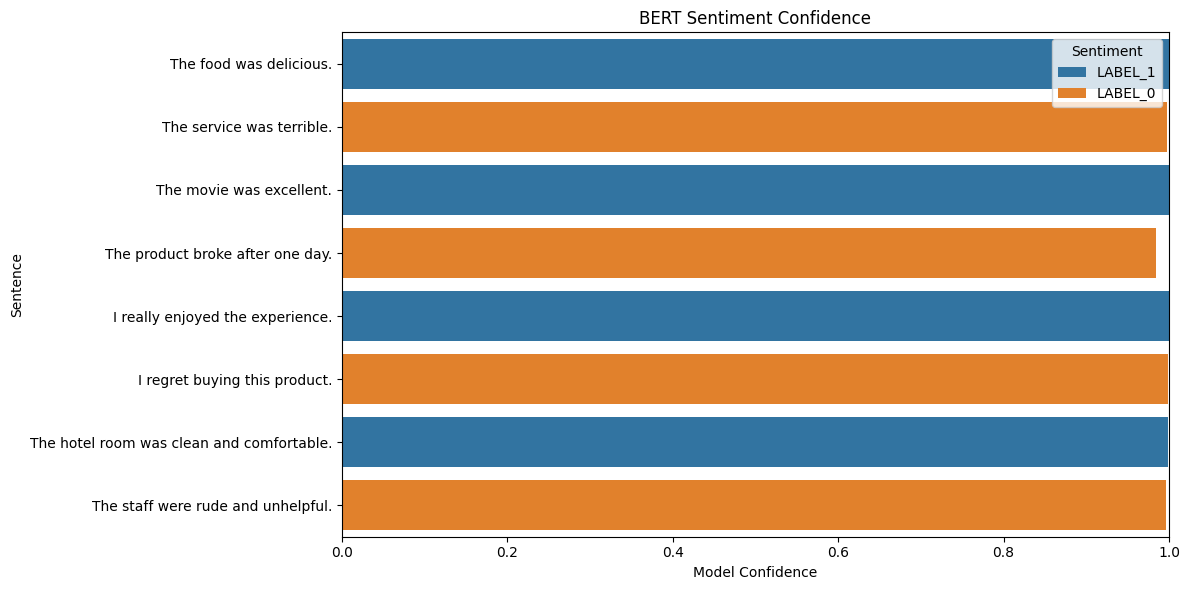


TRICKY SENTENCES

 I do not like this product.
LABEL_0 99.89%

 This is not bad.
LABEL_1 99.91%

 Great, another two-hour delay.
LABEL_0 97.63%

 I love the camera but hate the battery.
LABEL_0 99.01%

 The food was okay, nothing special.
LABEL_0 89.27%

 I expected better from such an expensive phone.
LABEL_0 98.94%


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/738M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

...

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:561: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(



ABSA model loaded!

FIRST ABSA EXAMPLE

Aspect: chicken
Sentiment: Positive
Confidence: 99.75%

Aspect: KFC
Sentiment: Negative
Confidence: 98.57%

BASIC ABSA RESULT


,Aspect,Sentiment,Confidence %
0,chicken,Positive,99.75
1,KFC,Negative,98.57



RESTAURANT ABSA


,Aspect,Sentiment,Confidence %
0,food,Positive,99.66
1,service,Negative,99.35
2,restaurant,Negative,99.68
3,price,Negative,98.76


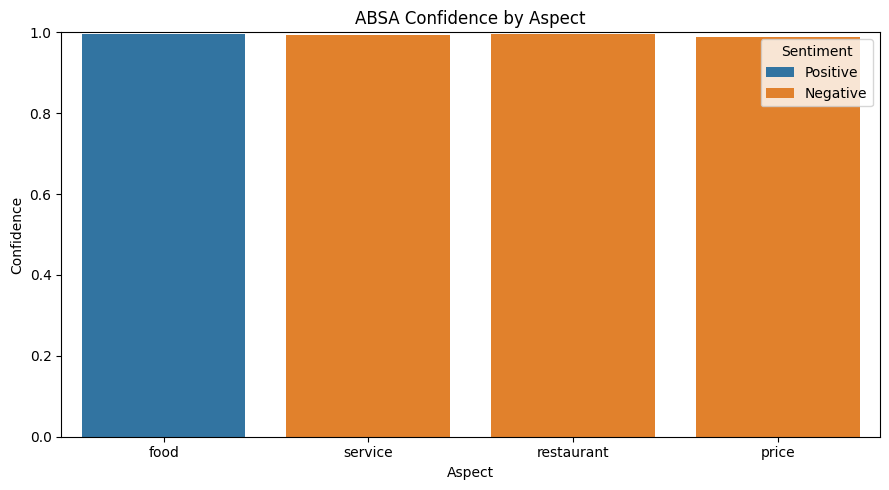


PRODUCT ABSA


,Aspect,Sentiment,Confidence %
0,camera quality,Positive,99.77
1,battery,Negative,99.11
2,phone design,Positive,99.35



AUTOMATICALLY EXTRACTED ASPECTS
['camera', 'battery', 'phone', 'design']

AUTOMATIC ABSA RESULT


,Aspect,Sentiment,Confidence %
0,camera,Positive,99.71
1,battery,Negative,99.16
2,phone,Positive,96.82
3,design,Positive,99.53



AUTOMATIC LAPTOP ABSA


,Aspect,Sentiment,Confidence %
0,laptop,Neutral,80.11
1,display,Positive,99.70
2,processor,Positive,99.62
3,battery,Negative,99.56
4,life,Negative,99.65
5,keyboard,Negative,99.60



MANUAL LAPTOP ABSA


,Aspect,Sentiment,Confidence %
0,display,Positive,99.70
1,processor,Positive,99.62
2,battery life,Negative,99.61
3,keyboard,Negative,99.60



FINAL ABSA RESULT


,Aspect,Sentiment,Confidence %
0,food,Positive,99.69
1,staff,Positive,99.42
2,service,Negative,99.51
3,prices,Negative,99.51


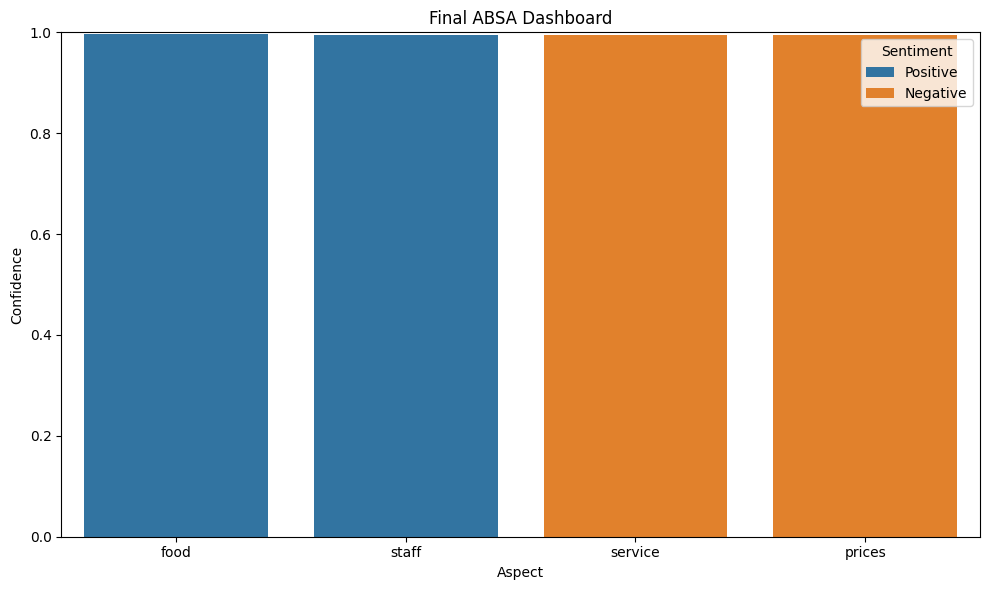


Enter a review: Good
Enter aspects separated by commas: 5

INTERACTIVE ABSA RESULT


,Aspect,Sentiment,Confidence %
0,5,Positive,99.31


In [ ]:
# ============================================================
# BERT SENTIMENT ANALYSIS + ABSA — COMPLETE CODE IN ONE CELL
# ============================================================

# ---------------------------
# 1. INSTALL REQUIRED PACKAGES
# ---------------------------

import sys
import subprocess

def run_pip(*packages):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *packages
    ])

subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision"],
    check=False
)

run_pip(
    "transformers==4.46.3",
    "sentencepiece>=0.2.0",
    "spacy>=3.7,<4",
    "seaborn>=0.13",
    "matplotlib>=3.8",
    "pandas>=2.2,<3"
)

subprocess.check_call([
    sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"
])


# ---------------------------
# 2. IMPORT LIBRARIES
# ---------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch
import transformers

from transformers import pipeline

nlp = spacy.load("en_core_web_sm")

DEVICE = 0 if torch.cuda.is_available() else -1

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())


# ---------------------------
# 3. TEST TRANSFORMERS
# ---------------------------

TEST_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"

test_pipeline = pipeline(
    "sentiment-analysis",
    model=TEST_MODEL,
    device=DEVICE
)

print("\nTransformer Test:")
print(test_pipeline("I love teaching artificial intelligence!"))


# ---------------------------
# 4. LOAD BERT SENTIMENT MODEL
# ---------------------------

MODEL_NAME = "textattack/bert-base-uncased-SST-2"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=DEVICE
)

print("\nBERT sentiment model loaded!")


# ---------------------------
# 5. TOKENIZATION
# ---------------------------

tokenizer = sentiment_pipeline.tokenizer

text = "I love this amazing chicken restaurant!"

tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("\nTOKENIZATION")
print("Text:", text)
print("Tokens:", tokens)
print("Token IDs:", token_ids)
print("Encoded:", tokenizer(text))


# ---------------------------
# 6. FIRST SENTIMENT PREDICTION
# ---------------------------

sentence = "I absolutely loved the food and the service."

result = sentiment_pipeline(sentence)[0]

print("\nFIRST PREDICTION")
print("Sentence:", sentence)
print("Sentiment:", result["label"])
print("Confidence:", f"{result['score']:.2%}")


# ---------------------------
# 7. SENTIMENT FUNCTION
# ---------------------------

def explain_sentiment(text):
    prediction = sentiment_pipeline(text)[0]

    print("\nText:", text)
    print("Sentiment:", prediction["label"])
    print("Confidence:", f"{prediction['score']:.2%}")

    return prediction


explain_sentiment("The movie was fantastic!")


# ---------------------------
# 8. MULTIPLE SENTENCES
# ---------------------------

sentences = [
    "The food was delicious.",
    "The service was terrible.",
    "The movie was excellent.",
    "The product broke after one day.",
    "I really enjoyed the experience.",
    "I regret buying this product.",
    "The hotel room was clean and comfortable.",
    "The staff were rude and unhelpful."
]

rows = []

for text in sentences:
    prediction = sentiment_pipeline(text)[0]

    rows.append({
        "Text": text,
        "Sentiment": prediction["label"],
        "Confidence": prediction["score"]
    })

classroom_df = pd.DataFrame(rows)

classroom_df["Confidence %"] = (
    classroom_df["Confidence"] * 100
).round(2)

print("\nMULTIPLE SENTIMENT RESULTS")
display(
    classroom_df[
        ["Text", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 9. SENTIMENT VISUALIZATION
# ---------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classroom_df,
    x="Confidence",
    y="Text",
    hue="Sentiment",
    dodge=False
)

plt.xlim(0, 1)
plt.xlabel("Model Confidence")
plt.ylabel("Sentence")
plt.title("BERT Sentiment Confidence")
plt.tight_layout()
plt.show()


# ---------------------------
# 10. TRICKY SENTENCES
# ---------------------------

tricky_sentences = [
    "I do not like this product.",
    "This is not bad.",
    "Great, another two-hour delay.",
    "I love the camera but hate the battery.",
    "The food was okay, nothing special.",
    "I expected better from such an expensive phone."
]

print("\nTRICKY SENTENCES")

for text in tricky_sentences:

    prediction = sentiment_pipeline(text)[0]

    print("\n", text)
    print(
        prediction["label"],
        f"{prediction['score']:.2%}"
    )


# ============================================================
# ABSA — ASPECT BASED SENTIMENT ANALYSIS
# ============================================================


# ---------------------------
# 11. LOAD ABSA MODEL
# ---------------------------

ABSA_MODEL = "yangheng/deberta-v3-base-absa-v1.1"

absa_pipeline = pipeline(
    "text-classification",
    model=ABSA_MODEL,
    tokenizer=ABSA_MODEL,
    device=DEVICE
)

print("\nABSA model loaded!")


# ---------------------------
# 12. FIRST ABSA EXAMPLE
# ---------------------------

sentence = "I love chicken but hate KFC."

aspects = [
    "chicken",
    "KFC"
]

print("\nFIRST ABSA EXAMPLE")

for aspect in aspects:

    result = absa_pipeline(
        sentence,
        text_pair=aspect
    )[0]

    print("\nAspect:", aspect)
    print("Sentiment:", result["label"])
    print("Confidence:", f"{result['score']:.2%}")


# ---------------------------
# 13. ABSA FUNCTION
# ---------------------------

def analyze_aspects(sentence, aspects):

    results = []

    for aspect in aspects:

        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(results)


# ---------------------------
# 14. BASIC ABSA TEST
# ---------------------------

sentence = "I love chicken but hate KFC."

aspects = [
    "chicken",
    "KFC"
]

result_df = analyze_aspects(
    sentence,
    aspects
)

result_df["Confidence %"] = (
    result_df["Confidence"] * 100
).round(2)

print("\nBASIC ABSA RESULT")

display(
    result_df[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 15. RESTAURANT REVIEW
# ---------------------------

sentence = (
    "The food was delicious, but the service was terrible "
    "and the restaurant was too expensive."
)

aspects = [
    "food",
    "service",
    "restaurant",
    "price"
]

restaurant_df = analyze_aspects(
    sentence,
    aspects
)

restaurant_df["Confidence %"] = (
    restaurant_df["Confidence"] * 100
).round(2)

print("\nRESTAURANT ABSA")

display(
    restaurant_df[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 16. ABSA VISUALIZATION
# ---------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=restaurant_df,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.ylabel("Confidence")
plt.title("ABSA Confidence by Aspect")
plt.tight_layout()
plt.show()


# ---------------------------
# 17. PRODUCT REVIEW EXAMPLE
# ---------------------------

challenge_sentence = (
    "The camera quality is excellent, "
    "the battery is terrible, "
    "and the phone design is beautiful."
)

challenge_aspects = [
    "camera quality",
    "battery",
    "phone design"
]

challenge_result = analyze_aspects(
    challenge_sentence,
    challenge_aspects
)

challenge_result["Confidence %"] = (
    challenge_result["Confidence"] * 100
).round(2)

print("\nPRODUCT ABSA")

display(
    challenge_result[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ============================================================
# AUTOMATIC ASPECT EXTRACTION
# ============================================================


# ---------------------------
# 18. EXTRACT NOUN ASPECTS
# ---------------------------

sentence = (
    "The camera is excellent, "
    "the battery is terrible, "
    "and the phone design is beautiful."
)

doc = nlp(sentence)

possible_aspects = []

for token in doc:

    if token.pos_ in ["NOUN", "PROPN"]:

        if token.text.lower() not in [
            aspect.lower()
            for aspect in possible_aspects
        ]:

            possible_aspects.append(token.text)

print("\nAUTOMATICALLY EXTRACTED ASPECTS")
print(possible_aspects)


# ---------------------------
# 19. AUTOMATIC ABSA FUNCTION
# ---------------------------

def automatic_absa(sentence):

    doc = nlp(sentence)

    aspects = []
    seen = set()

    for token in doc:

        if token.pos_ in ["NOUN", "PROPN"]:

            key = token.text.lower()

            if key not in seen:

                aspects.append(token.text)
                seen.add(key)

    results = []

    for aspect in aspects:

        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(
        results,
        columns=[
            "Aspect",
            "Sentiment",
            "Confidence"
        ]
    )


# ---------------------------
# 20. AUTOMATIC ABSA TEST
# ---------------------------

auto_result = automatic_absa(sentence)

if not auto_result.empty:

    auto_result["Confidence %"] = (
        auto_result["Confidence"] * 100
    ).round(2)

    print("\nAUTOMATIC ABSA RESULT")

    display(
        auto_result[
            ["Aspect", "Sentiment", "Confidence %"]
        ]
    )


# ---------------------------
# 21. LAPTOP REVIEW
# ---------------------------

product_review = (
    "The laptop has an excellent display "
    "and a fast processor, "
    "but the battery life is disappointing "
    "and the keyboard feels cheap."
)

product_result = automatic_absa(
    product_review
)

product_result["Confidence %"] = (
    product_result["Confidence"] * 100
).round(2)

print("\nAUTOMATIC LAPTOP ABSA")

display(
    product_result[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 22. MANUAL LAPTOP ASPECTS
# ---------------------------

manual_aspects = [
    "display",
    "processor",
    "battery life",
    "keyboard"
]

manual_result = analyze_aspects(
    product_review,
    manual_aspects
)

manual_result["Confidence %"] = (
    manual_result["Confidence"] * 100
).round(2)

print("\nMANUAL LAPTOP ABSA")

display(
    manual_result[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 23. FINAL REVIEW
# ---------------------------

final_review = (
    "The food was delicious, "
    "the staff were friendly, "
    "but the service was slow "
    "and the prices were too high."
)

final_aspects = [
    "food",
    "staff",
    "service",
    "prices"
]

final_result = analyze_aspects(
    final_review,
    final_aspects
)

final_result["Confidence %"] = (
    final_result["Confidence"] * 100
).round(2)

print("\nFINAL ABSA RESULT")

display(
    final_result[
        ["Aspect", "Sentiment", "Confidence %"]
    ]
)


# ---------------------------
# 24. FINAL VISUALIZATION
# ---------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_result,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.xlabel("Aspect")
plt.ylabel("Confidence")
plt.title("Final ABSA Dashboard")
plt.tight_layout()
plt.show()


# ============================================================
# 25. INTERACTIVE ABSA
# ============================================================

sentence = input("\nEnter a review: ")

aspects_input = input(
    "Enter aspects separated by commas: "
)

aspects = [
    aspect.strip()
    for aspect in aspects_input.split(",")
    if aspect.strip()
]

if aspects:

    interactive_df = analyze_aspects(
        sentence,
        aspects
    )

    interactive_df["Confidence %"] = (
        interactive_df["Confidence"] * 100
    ).round(2)

    print("\nINTERACTIVE ABSA RESULT")

    display(
        interactive_df[
            ["Aspect", "Sentiment", "Confidence %"]
        ]
    )

else:
    print("Please enter at least one aspect.")